[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch10_attention_transformer.ipynb)

# 10장 어텐션과 트랜스포머 · 실습 노트북
『보고, 읽고, 설명하는 딥러닝 — Colab에서 직접 만들며 배우는 딥러닝 응용』

영어 문장을 스페인어로 옮기는 번역기를 세 가지 방식으로 만들어 비교합니다.

1. 어텐션 계산 한눈에 보기 (10.2절)
2. 데이터 준비: 영어-스페인어 문장 쌍 (10.3절)
3. 실습 ①-1: LSTM 번역기 — 문맥 벡터 하나 (10.3절)
4. 실습 ①-2: LSTM + 어텐션 번역기, 어텐션 지도 (10.3절)
5. 셀프 어텐션을 숫자로 따라가기 (10.4절)
6. 실습 ②: 작은 트랜스포머 번역기 (10.6절)
7. 세 번역기 비교하기 (10.7절)

**런타임 → 런타임 유형 변경 → T4 GPU**로 바꾼 뒤 실행하세요. GPU에서 모두 실행하면 15분쯤 걸립니다.

## 0. 준비

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (Input, Embedding, LSTM, Dense, Dropout, Attention, Concatenate,
                                     MultiHeadAttention, LayerNormalization, TextVectorization)
from tensorflow.keras.callbacks import EarlyStopping
from nltk.translate.bleu_score import corpus_bleu

tf.keras.utils.set_random_seed(42)   # 실행할 때마다 같은 결과가 나오도록 시드 고정
print(tf.__version__, keras.__version__)

2.21.0 3.13.2


## 1. 어텐션 계산 한눈에 보기
인코더가 단어 4개를 읽고 만든 은닉 상태(길이 3의 벡터 4개)와, 디코더가 지금 무엇을 찾는지 나타내는 쿼리 벡터가 있다고 합시다.
쿼리와 각 은닉 상태의 내적(점수) → 소프트맥스(가중치) → 가중합(문맥 벡터) 순서로 계산합니다.

In [2]:
H = np.array([[1.0, 0.0, 0.5],    # 단어 1의 은닉 상태
              [0.0, 1.0, 0.0],    # 단어 2
              [0.9, 0.1, 0.4],    # 단어 3
              [0.0, 0.0, 1.0]])   # 단어 4
q = np.array([1.0, 0.0, 0.5])     # 쿼리: 지금 찾는 정보

score = H @ q                                   # 1) 점수: 쿼리와 각 은닉 상태의 내적
weight = np.exp(score) / np.exp(score).sum()    # 2) 소프트맥스 → 어텐션 가중치(합이 1)
context = weight @ H                            # 3) 가중합 → 문맥 벡터
print('점수  :', score.round(3))
print('가중치:', weight.round(3), '합', weight.sum().round(3))
print('문맥 벡터:', context.round(3))

점수  : [1.25 0.   1.1  0.5 ]
가중치: [0.382 0.109 0.329 0.18 ] 합 1.0
문맥 벡터: [0.677 0.142 0.503]


## 2. 데이터 준비: 영어-스페인어 문장 쌍
텐서플로 공식 번역 튜토리얼이 쓰는 문장 쌍(약 12만 개)입니다. Colab 무료 GPU에서 한 시간 안쪽으로 학습하도록 그중 2만 5천 쌍만 씁니다. 한 줄에 `영어 문장<탭>스페인어 문장`이 들어 있습니다.

In [3]:
!wget -q http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip
!unzip -oq spa-eng.zip

lines = open('spa-eng/spa.txt', encoding='utf-8').read().strip().split('\n')
pairs = [line.split('\t') for line in lines]
print(len(pairs))
for eng, spa in pairs[50000:50003]:
    print(eng, '→', spa)

118964
The place was almost empty. → El lugar estaba casi vacío.
The plane landed at Narita. → El avión aterrizó en Narita.
The plane took off at 2:30. → El avión despegó a las 2:30.


In [4]:
def clean(s):
    s = s.lower()
    s = re.sub(r'([?.!,¿¡])', r' \1 ', s)      # 문장 부호도 한 단어로 떼어 낸다
    return re.sub(r'\s+', ' ', s).strip()

pairs = [(clean(e), clean(s)) for e, s in pairs]
pairs = [(e, s) for e, s in pairs if len(e.split()) <= 20 and len(s.split()) <= 20]   # 20단어 이하만

rng = np.random.default_rng(0)
rng.shuffle(pairs)
test_pairs = pairs[:2000]              # 시험용 2,000쌍은 학습에 쓰지 않는다
train_pairs = pairs[2000:27000]        # 학습 시간을 줄이려고 2만 5천 쌍만 학습에 쓴다
print('전체', len(pairs), '/ 학습', len(train_pairs), '/ 테스트', len(test_pairs))
print(train_pairs[0])

전체 118639 / 학습 25000 / 테스트 2000
("i've been to australia once .", 'he estado una vez en australia .')


부록 B에서 소개한 `TextVectorization`으로 단어를 번호로 바꿉니다. 스페인어 문장에는 시작과 끝을 알리는 `[start]`, `[end]`를 붙입니다.
- 인코더 입력: 영어 문장 (22칸)
- 디코더 입력: `[start]` + 스페인어 문장 → 한 칸씩 밀린 것이 정답 (교사 강요, teacher forcing)

In [5]:
VOCAB = 8000      # 언어마다 많이 나온 단어 8,000개
L = 22            # 문장 길이 (부족하면 0으로 채움)

eng_vec = TextVectorization(max_tokens=VOCAB, standardize=None, output_sequence_length=L)
spa_vec = TextVectorization(max_tokens=VOCAB, standardize=None, output_sequence_length=L + 1)
eng_vec.adapt([e for e, s in train_pairs])
spa_vec.adapt(['[start] ' + s + ' [end]' for e, s in train_pairs])
spa_words = spa_vec.get_vocabulary()
START, END = spa_words.index('[start]'), spa_words.index('[end]')

X = eng_vec([e for e, s in train_pairs]).numpy()
Y = spa_vec(['[start] ' + s + ' [end]' for e, s in train_pairs]).numpy()
dec_in, dec_out = Y[:, :-1], Y[:, 1:]          # 디코더 입력과 정답(한 칸 뒤)
print(X.shape, dec_in.shape, dec_out.shape)
print(train_pairs[0][1])
print('디코더 입력:', dec_in[0][:8])
print('정답      :', dec_out[0][:8])

(25000, 22) (25000, 22) (25000, 22)
he estado una vez en australia .
디코더 입력: [  2  80 161  23  70  14 427   4]
정답      : [ 80 161  23  70  14 427   4   3]


번역은 단어를 하나씩 만들어 갑니다. 학습한 모델로 `[start]`부터 시작해, 가장 확률이 높은 단어를 골라 다음 입력으로 넣기를 `[end]`가 나올 때까지 되풀이합니다(그리디 디코딩).
번역 품질은 **BLEU** 점수로 잽니다. 모델 번역과 정답 번역이 1~4단어 묶음(n-gram)을 얼마나 함께 가졌는지 보는 점수로, 0~100이며 높을수록 좋습니다.

In [6]:
def translate(model, eng_sentences, batch=500):
    x = eng_vec(eng_sentences).numpy()
    y = np.zeros((len(x), L), dtype='int64')
    y[:, 0] = START
    for t in range(L - 1):                                   # 한 단어씩 만들어 다음 입력으로
        for b in range(0, len(x), batch):
            p = model([x[b:b+batch], y[b:b+batch]], training=False)
            y[b:b+batch, t + 1] = np.argmax(p[:, t], axis=-1)
    out = []
    for row in y[:, 1:]:
        words = []
        for i in row:
            if i == END or i == 0:
                break
            words.append(spa_words[i])
        out.append(words)
    return out

test_eng = [e for e, s in test_pairs]
refs = [[s.split()] for e, s in test_pairs]
n_words = np.array([len(e.split()) for e in test_eng])
groups = {'5단어 이하': n_words <= 5, '6~10단어': (n_words >= 6) & (n_words <= 10), '11단어 이상': n_words >= 11}
print({k: int(v.sum()) for k, v in groups.items()})

def evaluate_bleu(model, name):
    hyps = translate(model, test_eng)
    total = corpus_bleu(refs, hyps) * 100
    by_len = {k: corpus_bleu([refs[i] for i in np.where(g)[0]], [hyps[i] for i in np.where(g)[0]]) * 100
              for k, g in groups.items()}
    print(f'{name}: BLEU {total:.1f} |', ' | '.join(f'{k} {v:.1f}' for k, v in by_len.items()))
    return hyps, total, by_len

def masked_acc(y_true, y_pred):                     # 패딩(0)을 뺀 단어 정확도
    mask = tf.cast(y_true > 0, 'float32')
    hit = tf.cast(tf.equal(tf.cast(y_true, 'int64'), tf.argmax(y_pred, -1)), 'float32')
    return tf.reduce_sum(hit * mask) / tf.reduce_sum(mask)

loss_fn = keras.losses.SparseCategoricalCrossentropy(ignore_class=0)   # 패딩 자리는 손실에서 뺀다
results = {}

{'5단어 이하': 464, '6~10단어': 1302, '11단어 이상': 234}


## 3. 실습 ①-1: LSTM 번역기 — 문맥 벡터 하나
인코더 LSTM이 영어 문장을 끝까지 읽고 남긴 마지막 상태(문맥 벡터)만 디코더에 넘겨줍니다(10.1절).

In [7]:
UNITS = 256

def make_seq2seq(use_attention):
    enc_in = Input(shape=(L,), name='english')
    dec_in = Input(shape=(L,), name='spanish_in')
    e = Embedding(VOCAB, UNITS, mask_zero=True)(enc_in)
    enc_seq, h, c = LSTM(UNITS, return_sequences=True, return_state=True)(e)   # 시점마다 은닉 상태 + 마지막 상태
    d = Embedding(VOCAB, UNITS)(dec_in)
    dec_seq = LSTM(UNITS, return_sequences=True)(d, initial_state=[h, c])       # 마지막 상태(문맥 벡터)로 시작
    scores = None
    if use_attention:
        # 디코더의 시점마다(쿼리) 인코더의 모든 은닉 상태(키·값)를 보고 문맥 벡터를 새로 만든다
        context, scores = Attention()([dec_seq, enc_seq], return_attention_scores=True)
        dec_seq = Dense(UNITS, activation='tanh')(Concatenate()([dec_seq, context]))
    out = Dense(VOCAB, activation='softmax')(Dropout(0.2)(dec_seq))
    model = Model([enc_in, dec_in], out)
    att_model = Model([enc_in, dec_in], scores) if use_attention else None   # 어텐션 가중치를 꺼내는 모델
    return model, att_model

def train(model):
    model.compile(optimizer='adam', loss=loss_fn, metrics=[masked_acc])
    return model.fit([X, dec_in], dec_out, batch_size=64, epochs=10, validation_split=0.1,
                     callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)], verbose=2)

tf.keras.utils.set_random_seed(42)
lstm, _ = make_seq2seq(use_attention=False)
lstm.summary()
h_lstm = train(lstm)
results['LSTM'] = evaluate_bleu(lstm, 'LSTM')

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, 22)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spanish_in          │ (None, 22)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 22, 256)   │  2,048,000 │ english[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 22)        │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 22, 256)   │  2,048,000 │ spanish_in[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 22, 256), │    525,312 │ embedding[0][0],  │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 22, 256)   │    525,312 │ embedding_1[0][0… │
│                     │                   │            │ lstm[0][1],       │
│                     │                   │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 22, 256)   │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 22, 8000)  │  2,056,000 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,202,624 (27.48 MB)

 Trainable params: 7,202,624 (27.48 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
352/352 - 24s - 67ms/step - loss: 5.1538 - masked_acc: 0.2485 - val_loss: 4.5730 - val_masked_acc: 0.2970
Epoch 2/10
352/352 - 15s - 43ms/step - loss: 4.3400 - masked_acc: 0.3236 - val_loss: 4.1743 - val_masked_acc: 0.3453
Epoch 3/10
352/352 - 15s - 43ms/step - loss: 3.9339 - masked_acc: 0.3664 - val_loss: 3.8628 - val_masked_acc: 0.3858
Epoch 4/10
352/352 - 15s - 43ms/step - loss: 3.6060 - masked_acc: 0.4014 - val_loss: 3.6325 - val_masked_acc: 0.4138
Epoch 5/10
352/352 - 15s - 43ms/step - loss: 3.3284 - masked_acc: 0.4304 - val_loss: 3.4386 - val_masked_acc: 0.4347
Epoch 6/10
352/352 - 15s - 43ms/step - loss: 3.0735 - masked_acc: 0.4564 - val_loss: 3.2846 - val_masked_acc: 0.4528
Epoch 7/10
352/352 - 15s - 43ms/step - loss: 2.8454 - masked_acc: 0.4804 - val_loss: 3.1558 - val_masked_acc: 0.4680
Epoch 8/10
352/352 - 15s - 43ms/step - loss: 2.6406 - masked_acc: 0.5017 - val_loss: 3.0575 - val_masked_acc: 0.4843
Epoch 9/10
352/352 - 15s - 43ms/step - loss: 2.4539 - masked_acc

## 4. 실습 ①-2: LSTM + 어텐션 번역기
같은 모델에 `Attention` 층 하나를 더합니다. 디코더가 단어를 만들 때마다 인코더의 모든 은닉 상태를 다시 봅니다.

In [8]:
tf.keras.utils.set_random_seed(42)
att, att_scores = make_seq2seq(use_attention=True)
att.summary()
h_att = train(att)
results['LSTM + Attention'] = evaluate_bleu(att, 'LSTM + Attention')

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, 22)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spanish_in          │ (None, 22)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 22, 256)   │  2,048,000 │ english[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 22)        │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 22, 256)   │  2,048,000 │ spanish_in[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 22, 256), │    525,312 │ embedding_2[0][0… │
│                     │ (None, 256),      │            │ not_equal_1[0][0] │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 22, 256)   │    525,312 │ embedding_3[0][0… │
│                     │                   │            │ lstm_2[0][1],     │
│                     │                   │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 22, 256), │          0 │ lstm_3[0][0],     │
│ (Attention)         │ (None, 22, 22)]   │            │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 22, 512)   │          0 │ lstm_3[0][0],     │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 22, 256)   │    131,328 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 22, 256)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 22, 8000)  │  2,056,000 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,333,952 (27.98 MB)

 Trainable params: 7,333,952 (27.98 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
352/352 - 18s - 52ms/step - loss: 5.6750 - masked_acc: 0.1644 - val_loss: 5.1705 - val_masked_acc: 0.2478
Epoch 2/10
352/352 - 16s - 45ms/step - loss: 4.8662 - masked_acc: 0.2821 - val_loss: 4.5379 - val_masked_acc: 0.3152
Epoch 3/10
352/352 - 16s - 45ms/step - loss: 4.2629 - masked_acc: 0.3399 - val_loss: 4.0631 - val_masked_acc: 0.3671
Epoch 4/10
352/352 - 16s - 44ms/step - loss: 3.7751 - masked_acc: 0.3872 - val_loss: 3.7138 - val_masked_acc: 0.4026
Epoch 5/10
352/352 - 16s - 44ms/step - loss: 3.3575 - masked_acc: 0.4278 - val_loss: 3.4202 - val_masked_acc: 0.4402
Epoch 6/10
352/352 - 16s - 45ms/step - loss: 2.9538 - masked_acc: 0.4752 - val_loss: 3.1144 - val_masked_acc: 0.4856
Epoch 7/10
352/352 - 16s - 45ms/step - loss: 2.5453 - masked_acc: 0.5299 - val_loss: 2.8218 - val_masked_acc: 0.5300
Epoch 8/10
352/352 - 16s - 45ms/step - loss: 2.1712 - masked_acc: 0.5839 - val_loss: 2.6152 - val_masked_acc: 0.5649
Epoch 9/10
352/352 - 16s - 45ms/step - loss: 1.8561 - masked_acc

### 어텐션 지도
번역한 문장의 스페인어 단어(행)마다 영어 단어(열)에 준 가중치를 그립니다. 밝을수록 그 영어 단어를 많이 보았다는 뜻입니다.

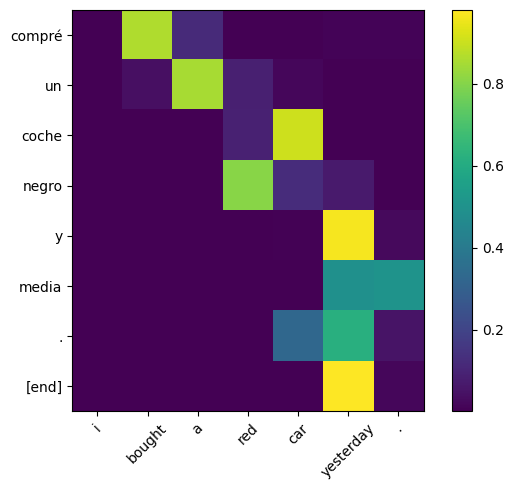

i bought a red car yesterday . → compré un coche negro y media .


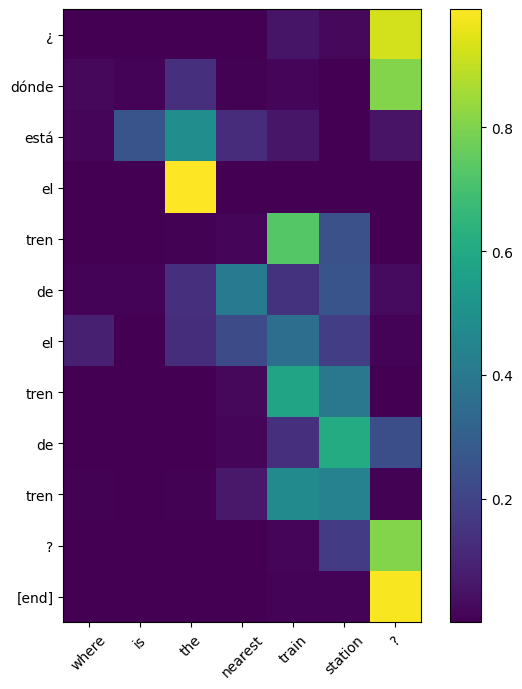

where is the nearest train station ? → ¿ dónde está el tren de el tren de tren ?


In [9]:
def attention_map(sentence):
    words = translate(att, [sentence])[0]
    x = eng_vec([sentence]).numpy()
    y = spa_vec(['[start] ' + ' '.join(words)]).numpy()[:, :L]
    a = att_scores([x, y], training=False).numpy()[0]        # (스페인어 자리, 영어 자리)
    eng = sentence.split()
    a = a[:len(words) + 1, :len(eng)]                        # [end]까지
    plt.figure(figsize=(0.6 * len(eng) + 2, 0.5 * len(a) + 1))
    plt.imshow(a, cmap='viridis')
    plt.xticks(range(len(eng)), eng, rotation=45)
    plt.yticks(range(len(a)), words + ['[end]'])
    plt.colorbar(); plt.tight_layout(); plt.show()
    return words, a

for s in ['i bought a red car yesterday .', 'where is the nearest train station ?']:
    w, a = attention_map(s)
    print(s, '→', ' '.join(w))

## 5. 셀프 어텐션을 숫자로 따라가기
"동물이 길을 건너지 않았다 그것은 지쳤다"에서 '그것은'이 누구를 보는지 계산합니다.
실제 모델은 쿼리·키·값을 학습으로 만들지만, 여기서는 뜻이 보이도록 작은 숫자를 직접 정했습니다.

In [10]:
words = ['동물이', '길을', '건너지', '않았다', '그것은', '지쳤다']
# 단어마다 쿼리·키·값 (원래는 단어 벡터에 W_Q, W_K, W_V를 곱해 얻는다. 여기서는 뜻이 보이도록 직접 정함)
# 키의 두 칸: [살아 있는 것, 장소·사물]
K = np.array([[2, 0],    # 동물이: 살아 있는 것
              [0, 2],    # 길을: 장소
              [0, 1],    # 건너지: 장소와 관련
              [0, 0],    # 않았다
              [1, 0],    # 그것은: 살아 있는 것을 가리킴
              [1, 0]])   # 지쳤다: 살아 있는 것과 관련된 동사
# 값의 세 칸: [동물, 길, 행동·상태]
V = np.array([[1, 0, 0],    # 동물이
              [0, 1, 0],    # 길을
              [0, 0, 1],    # 건너지
              [0, 0, 1],    # 않았다
              [0, 0, 0],    # 그것은: 대명사 자체에는 내용이 없다
              [0, 0, 1]])   # 지쳤다
q = np.array([2, 0])        # '그것은'의 쿼리: 가리킬 '살아 있는 것'을 찾는다

d_k = len(q)
score = K @ q                                   # ① 점수: 쿼리와 각 키의 내적
scaled = score / np.sqrt(d_k)                   # ② √d_k로 나누기
weight = np.exp(scaled) / np.exp(scaled).sum()  # ③ 소프트맥스 → 가중치(합 1)
out = weight @ V                                # ④ 값의 가중합 → '그것은'의 새 표현
for w, s, c, a in zip(words, score, scaled, weight):
    print(f'{w:5s} 점수 {s}  ÷√2 {c:.2f}  가중치 {a:.3f}')
print("'그것은'의 새 표현 [동물, 길, 행동·상태]:", out.round(3))

동물이   점수 4  ÷√2 2.83  가중치 0.601
길을    점수 0  ÷√2 0.00  가중치 0.036
건너지   점수 0  ÷√2 0.00  가중치 0.036
않았다   점수 0  ÷√2 0.00  가중치 0.036
그것은   점수 2  ÷√2 1.41  가중치 0.146
지쳤다   점수 2  ÷√2 1.41  가중치 0.146
'그것은'의 새 표현 [동물, 길, 행동·상태]: [0.601 0.036 0.217]


여섯 단어 모두의 쿼리를 정해 행렬로 한 번에 계산합니다: softmax(QKᵀ/√d_k)·V

In [11]:
Q = np.array([[0, 0],    # 동물이: 특별히 찾는 것 없음
              [0, 0],    # 길을
              [1, 1],    # 건너지: 누가, 어디를?
              [0, 0],    # 않았다
              [2, 0],    # 그것은: 가리킬 '살아 있는 것'
              [2, 0]])   # 지쳤다: 누가 지쳤나?
S = Q @ K.T / np.sqrt(d_k)                              # 6×6 점수표: 행 = 묻는 단어, 열 = 답하는 단어
A = np.exp(S) / np.exp(S).sum(axis=1, keepdims=True)    # 행마다 소프트맥스
Z = A @ V                                               # 모든 단어의 새 표현을 한 번에
print('Q', Q.shape, ' K.T', K.T.shape, ' QK^T', S.shape, ' V', V.shape, ' 결과', Z.shape)
print('가중치 행렬 A (행 = 묻는 단어):')
for w, row in zip(words, A):
    print(f'{w:5s}', row.round(2))
print("'그것은' 행이 앞 셀과 같은가:", np.allclose(A[4], weight))

Q (6, 2)  K.T (2, 6)  QK^T (6, 6)  V (6, 3)  결과 (6, 3)
가중치 행렬 A (행 = 묻는 단어):
동물이   [0.17 0.17 0.17 0.17 0.17 0.17]
길을    [0.17 0.17 0.17 0.17 0.17 0.17]
건너지   [0.27 0.27 0.13 0.07 0.13 0.13]
않았다   [0.17 0.17 0.17 0.17 0.17 0.17]
그것은   [0.6  0.04 0.04 0.04 0.15 0.15]
지쳤다   [0.6  0.04 0.04 0.04 0.15 0.15]
'그것은' 행이 앞 셀과 같은가: True


## 6. 실습 ②: 작은 트랜스포머 번역기
순환 신경망 없이 어텐션만으로 번역합니다. 인코더 블록 1개와 디코더 블록 1개입니다(10.5절).
- 인코더: 셀프 어텐션 → 피드포워드 (각각 잔차 연결 + 층 정규화)
- 디코더: 마스크드 셀프 어텐션 → 인코더-디코더 어텐션 → 피드포워드

In [12]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, mask_zero=False, **kwargs):
        super().__init__(**kwargs)
        self.token_emb = Embedding(VOCAB, UNITS, mask_zero=mask_zero)   # 단어 임베딩
        self.pos_emb = Embedding(L, UNITS)                              # 위치 임베딩: 0, 1, 2, ... 번째 자리
    def call(self, x):
        positions = tf.range(tf.shape(x)[-1])
        return self.token_emb(x) + self.pos_emb(positions)
    def compute_mask(self, x, mask=None):
        return self.token_emb.compute_mask(x)

def make_transformer(num_heads=4, ff_dim=512):
    enc_in = Input(shape=(L,), name='english')
    dec_in = Input(shape=(L,), name='spanish_in')
    # 인코더 블록
    x = PositionalEmbedding(mask_zero=True)(enc_in)       # 패딩(0) 자리는 어텐션에서 보지 않는다
    a = MultiHeadAttention(num_heads, UNITS // num_heads)(x, x)                 # 셀프 어텐션
    x = LayerNormalization()(x + Dropout(0.1)(a))                               # 잔차 연결 + 층 정규화
    f = Dense(UNITS)(Dense(ff_dim, activation='relu')(x))                       # 피드포워드
    enc_out = LayerNormalization()(x + Dropout(0.1)(f))
    # 디코더 블록
    y = PositionalEmbedding()(dec_in)
    a = MultiHeadAttention(num_heads, UNITS // num_heads)(y, y, use_causal_mask=True)   # 마스크드 셀프 어텐션
    y = LayerNormalization()(y + Dropout(0.1)(a))
    a = MultiHeadAttention(num_heads, UNITS // num_heads)(y, enc_out)           # 인코더-디코더 어텐션
    y = LayerNormalization()(y + Dropout(0.1)(a))
    f = Dense(UNITS)(Dense(ff_dim, activation='relu')(y))
    y = LayerNormalization()(y + Dropout(0.1)(f))
    out = Dense(VOCAB, activation='softmax')(Dropout(0.2)(y))
    return Model([enc_in, dec_in], out)

tf.keras.utils.set_random_seed(42)
trf = make_transformer()
trf.summary()
h_trf = train(trf)
results['Transformer'] = evaluate_bleu(trf, 'Transformer')

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, 22)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 22, 256)   │  2,053,632 │ english[0][0]     │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 22, 256)   │    263,168 │ positional_embed… │
│ (MultiHeadAttentio… │                   │            │ positional_embed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 22, 256)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 22, 256)   │          0 │ positional_embed… │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spanish_in          │ (None, 22)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 22, 256)   │        512 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 22, 256)   │  2,053,632 │ spanish_in[0][0]  │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 22, 512)   │    131,584 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 22, 256)   │    263,168 │ positional_embed… │
│ (MultiHeadAttentio… │                   │            │ positional_embed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 22, 256)   │    131,328 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 22, 256)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 22, 256)   │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 22, 256)   │          0 │ positional_embed… │
│                     │                   │            │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 22, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 22, 256)   │        512 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 22, 256)   │        512 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 22, 256)   │    263,168 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,481,152 (28.54 MB)

 Trainable params: 7,481,152 (28.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
352/352 - 47s - 133ms/step - loss: 4.0745 - masked_acc: 0.3905 - val_loss: 3.0240 - val_masked_acc: 0.5063
Epoch 2/10
352/352 - 8s - 24ms/step - loss: 2.5205 - masked_acc: 0.5659 - val_loss: 2.3914 - val_masked_acc: 0.6006
Epoch 3/10
352/352 - 8s - 24ms/step - loss: 1.7606 - masked_acc: 0.6620 - val_loss: 2.1650 - val_masked_acc: 0.6270
Epoch 4/10
352/352 - 9s - 24ms/step - loss: 1.3057 - masked_acc: 0.7222 - val_loss: 2.1324 - val_masked_acc: 0.6394
Epoch 5/10
352/352 - 9s - 24ms/step - loss: 1.0136 - masked_acc: 0.7668 - val_loss: 2.1317 - val_masked_acc: 0.6552
Epoch 6/10
352/352 - 8s - 24ms/step - loss: 0.8161 - masked_acc: 0.8026 - val_loss: 2.1537 - val_masked_acc: 0.6548
Epoch 7/10
352/352 - 8s - 24ms/step - loss: 0.6836 - masked_acc: 0.8287 - val_loss: 2.1942 - val_masked_acc: 0.6543
Transformer: BLEU 26.3 | 5단어 이하 29.8 | 6~10단어 27.8 | 11단어 이상 19.6


## 7. 세 번역기 비교하기

            LSTM  BLEU   7.4    8.5    8.2    4.1
LSTM + Attention  BLEU  18.5   17.1   20.2   13.5
     Transformer  BLEU  26.3   29.8   27.8   19.6
에포크 수: {'LSTM': 10, 'LSTM + Attention': 10, 'Transformer': 7}
파라미터 : {'LSTM': 7202624, 'LSTM + Attention': 7333952, 'Transformer': 7481152}


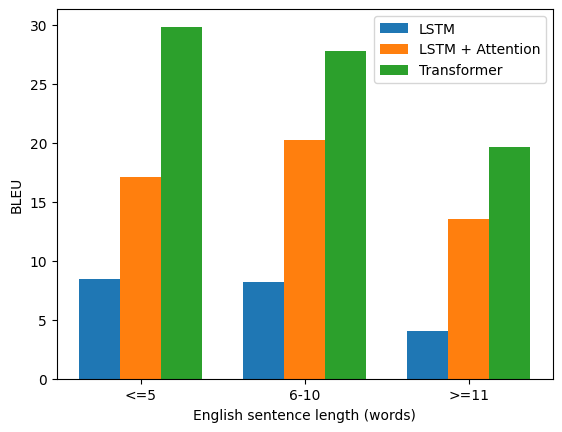

In [13]:
names = list(results)
for name in names:
    _, total, by_len = results[name]
    print(f'{name:>16s}  BLEU {total:5.1f}  ' + '  '.join(f'{v:5.1f}' for v in by_len.values()))
print('에포크 수:', {n: len(h.history['loss']) for n, h in zip(names, [h_lstm, h_att, h_trf])})
print('파라미터 :', {n: m.count_params() for n, m in zip(names, [lstm, att, trf])})

w = 0.25
for k, name in enumerate(names):
    vals = list(results[name][2].values())
    plt.bar(np.arange(3) + (k - 1) * w, vals, w, label=name)
plt.xticks(range(3), ['<=5', '6-10', '>=11'])
plt.xlabel('English sentence length (words)'); plt.ylabel('BLEU')
plt.legend(); plt.show()

In [14]:
for i in [1229, 1284, 1691, 1369, 1946]:
    print('영어  :', test_pairs[i][0])
    print('정답  :', test_pairs[i][1])
    for name in names:
        print(f'{name:>16s}:', ' '.join(results[name][0][i]))
    print()

영어  : tom wanted to spend the rest of his life with mary .
정답  : tom quería pasar el resto de su vida con mary .
            LSTM: tom quería hablar con mary en su hijo de su hijo .
LSTM + Attention: tom quería que los [UNK] de su vida con mary .
     Transformer: tom quería pasar el resto de su vida con mary .

영어  : tom received a letter from mary this morning .
정답  : tom recibió una carta de mary esta mañana .
            LSTM: tom le compró una carta a tom en la casa .
LSTM + Attention: tom se dio una carta de mary esta mañana .
     Transformer: tom recibió una carta de mary esta mañana .

영어  : she lived a quiet life in the country .
정답  : ella vivió una vida tranquila en el campo .
            LSTM: ella se [UNK] de una [UNK] de la vida de [UNK] .
LSTM + Attention: ella se quedó muy fácil en la vida en el campo .
     Transformer: ella vivió una vida tranquila en el campo .

영어  : i'm not the only one who can do that .
정답  : no soy el único que puede hacer eso .
            LSTM

## 실습
1. **내 문장 번역하기**: `translate(m, ['...'])`의 `m`에 `lstm`, `att`, `trf`를 차례로 넣어, 직접 만든 영어 문장의 번역을 세 모델로 비교해 보세요. 사전(8,000단어)에 없는 단어는 `[UNK]`로 바뀝니다.
2. **헤드 수 바꾸기**: `make_transformer(num_heads=8)`로 바꿔 학습하고 BLEU를 비교해 보세요.
3. **9장 로이터 분류에 어텐션 붙이기**: 9장 LSTM 분류기의 마지막 은닉 상태를 쿼리로, 모든 시점의 은닉 상태를 키·값으로 하는 어텐션을 붙여 테스트 정확도를 9장(70.66%)과 비교해 보세요.

먼저 직접 해 본 뒤, 아래 예시 답안과 비교해 보세요.

In [15]:
# 직접 작성해 보세요


### 예시 답안

In [16]:
# 1. 내 문장 번역하기
mine = ['i like to read books .', 'my brother is taller than me .', 'can you help me tomorrow ?']
for name, m in zip(names, [lstm, att, trf]):
    print(f'{name:>16s}:', [' '.join(t) for t in translate(m, mine)])

            LSTM: ['me gusta jugar al tenis .', 'mi padre es un hombre que yo .', '¿ puedes ir a la escuela ?']
LSTM + Attention: ['me gusta leer libros .', 'mi hermano es más alto que yo .', '¿ puedes ayudarme mañana ?']
     Transformer: ['me gusta leer libros .', 'mi hermano es más alto que yo .', '¿ puedes ayudarme mañana ?']


In [17]:
# 2. 헤드 수 바꾸기
tf.keras.utils.set_random_seed(42)
trf8 = make_transformer(num_heads=8)
train(trf8)
_ = evaluate_bleu(trf8, 'Transformer (heads 8)')

Epoch 1/10
352/352 - 37s - 106ms/step - loss: 4.1301 - masked_acc: 0.3798 - val_loss: 3.0765 - val_masked_acc: 0.4996
Epoch 2/10
352/352 - 9s - 25ms/step - loss: 2.5674 - masked_acc: 0.5569 - val_loss: 2.4208 - val_masked_acc: 0.5940
Epoch 3/10
352/352 - 9s - 25ms/step - loss: 1.7858 - masked_acc: 0.6580 - val_loss: 2.1780 - val_masked_acc: 0.6334
Epoch 4/10
352/352 - 9s - 25ms/step - loss: 1.3046 - masked_acc: 0.7229 - val_loss: 2.1274 - val_masked_acc: 0.6423
Epoch 5/10
352/352 - 9s - 25ms/step - loss: 1.0008 - masked_acc: 0.7704 - val_loss: 2.1294 - val_masked_acc: 0.6509
Epoch 6/10
352/352 - 9s - 24ms/step - loss: 0.7987 - masked_acc: 0.8062 - val_loss: 2.1576 - val_masked_acc: 0.6585
Transformer (heads 8): BLEU 26.7 | 5단어 이하 28.4 | 6~10단어 28.7 | 11단어 이상 19.6


In [18]:
# 3. 9장 로이터 분류에 어텐션 붙이기
from tensorflow.keras.datasets import reuters
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.utils import to_categorical

(X_train, y_train), (X_test, y_test) = reuters.load_data(num_words=1000, test_split=0.2)
X_train = sequence.pad_sequences(X_train, maxlen=100)
X_test = sequence.pad_sequences(X_test, maxlen=100)
y_train, y_test = to_categorical(y_train), to_categorical(y_test)

tf.keras.utils.set_random_seed(42)
inp = Input(shape=(100,))
seq = LSTM(100, return_sequences=True)(Embedding(1000, 100)(inp))   # 시점마다 은닉 상태
query = seq[:, -1:, :]                                               # 쿼리 = 마지막 은닉 상태
context = Attention()([query, seq])[:, 0, :]                         # 모든 시점을 보고 만든 문맥 벡터
out = Dense(46, activation='softmax')(Concatenate()([context, seq[:, -1, :]]))
clf = Model(inp, out)
clf.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
clf.fit(X_train, y_train, batch_size=20, epochs=200, validation_split=0.2,
        callbacks=[EarlyStopping(monitor='val_loss', patience=5)], verbose=0)
print('Test Accuracy: %.4f' % clf.evaluate(X_test, y_test, verbose=0)[1])

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Test Accuracy: 0.7133
